In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

import os
from pathlib import Path
os.chdir(Path().cwd().parent.parent)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from geo6.io.io import load_data
from geo6.config.config import Config

config = Config()

In [3]:
data = load_data()

## H1: Differences in microbial basal respiration
Do respiration rates differ between soil groups?

In [4]:
from geo6.plot.plot import save_plot, plot_basal_resp_boxplot, plot_basal_resp_rootextract_boxplot

### Basal respiration

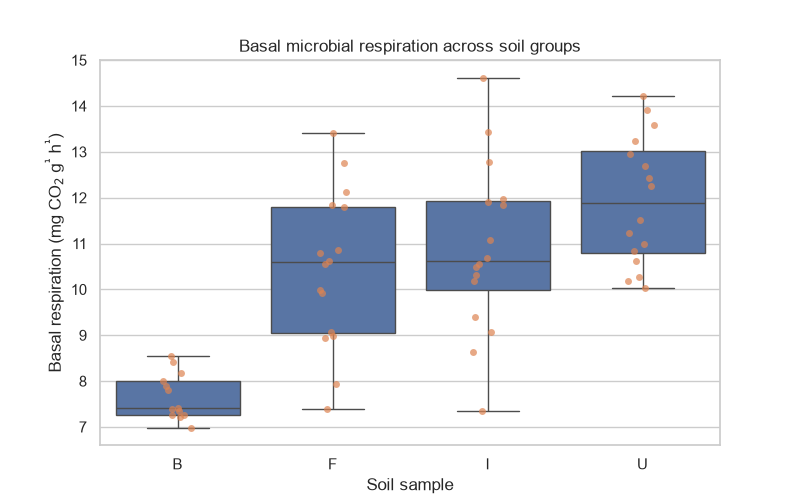

In [20]:
subset = microresp[["sample", "subrep", "br_mg_per_g_h"]]

plot = plot_basal_resp_boxplot(df=subset)
save_plot(plot=plot, name="basal_resp_boxplot")

No ANOVA since independence of variables is not given. We are measuring more the variance of the method than of the groups since we made one big mixture pot.

But if bulk was collected fro only one place this would explain the variance in the other groups and then show variance in sample location, rather than groups or masking those effects.

### Basal respiration root extract

In [22]:
subset = microresp[[
    'sample',
    "subrep",
    
    # 'br_mg_per_g_h',
    
    'br_I1_mg_per_g_h',
    'br_U1_mg_per_g_h',
    'br_F1_mg_per_g_h',
    
    'br_I2_mg_per_g_h',
    'br_U2_mg_per_g_h',
    'br_F2_mg_per_g_h',
]]

In [23]:
def melt_root_subset(df: pd.DataFrame) -> pd.DataFrame:
    respiration_cols = [
        col for col in df.columns
        if col.startswith("br_") and col.endswith("_mg_per_g_h")
    ]

    respiration = df.melt(
        id_vars=["sample", "subrep"],
        value_vars=respiration_cols,
        var_name="condition",
        value_name="respiration",
    ).dropna(subset=["respiration"])
    

    respiration[["extract", "concentration"]] = (
        respiration["condition"]
        .str.extract(r"br_([IUF])([12])_mg_per_g_h")
    )
    
    respiration["concentration"] = (
        respiration["concentration"].astype(int)
    )
    
    return respiration

subset_melt = melt_root_subset(df=subset)

# display(subset_melt)

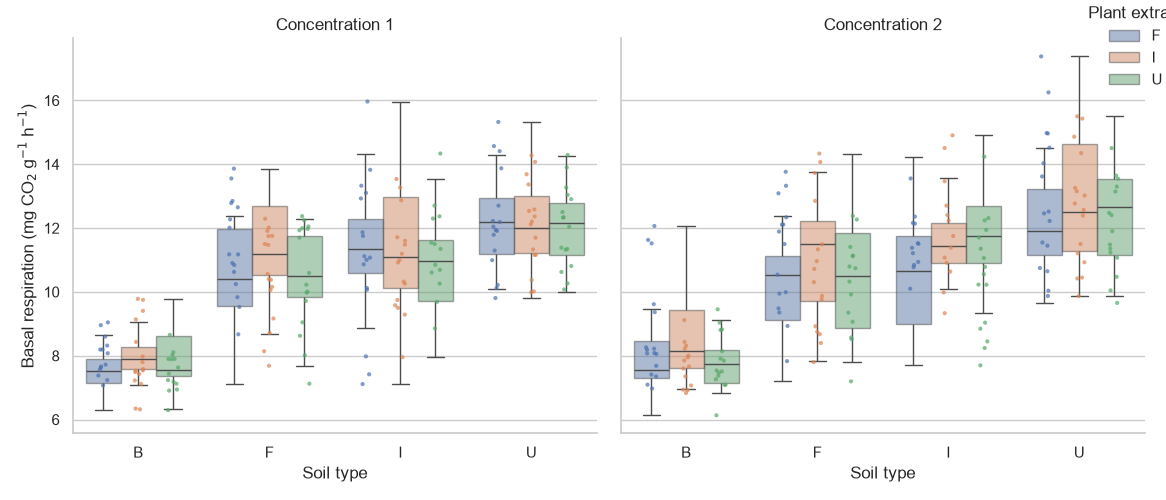

In [24]:
plot = plot_basal_resp_rootextract_boxplot(df=subset_melt)
save_plot(plot=plot, name="basal_resp_rootextract_boxplot")

## H2: Differences in substrate-use profiles

In [62]:
from geo6.plot.plot import plot_sir_boxplots

In [ ]:
microresp = data.microresp

subset = microresp[[
    "sample",
    'sir_1_mg_per_g_h',
    'sir_2_mg_per_g_h',
    'sir_3_mg_per_g_h',
    'sir_4_mg_per_g_h',
    'sir_5_mg_per_g_h',
    'sir_6_mg_per_g_h',
    'sir_7_mg_per_g_h',
    'sir_8_mg_per_g_h',
    'sir_9_mg_per_g_h',
    'sir_10_mg_per_g_h',
    'sir_11_mg_per_g_h',
]]

substance_mapping = {
    'sir_1_mg_per_g_h': "D-(+) Glucose",
    'sir_2_mg_per_g_h': "D-(+) Galactose",
    'sir_3_mg_per_g_h': "D-(+) Trehalose",
    'sir_4_mg_per_g_h': "a-Cyclodextrin",
    'sir_5_mg_per_g_h': "L-Alanine",
    'sir_6_mg_per_g_h': "L-Arginine",
    'sir_7_mg_per_g_h': "L-Phenylalanine",
    'sir_8_mg_per_g_h': "g-Amino buturic acid",
    'sir_9_mg_per_g_h': "Oxalic acid",
    'sir_10_mg_per_g_h': "Tri sodium citrat dihydrate",
    'sir_11_mg_per_g_h': "Lignin alkali",
}

subset_melt = subset.melt(id_vars = "sample")
subset_melt["substance"] = subset_melt["variable"].map(substance_mapping)

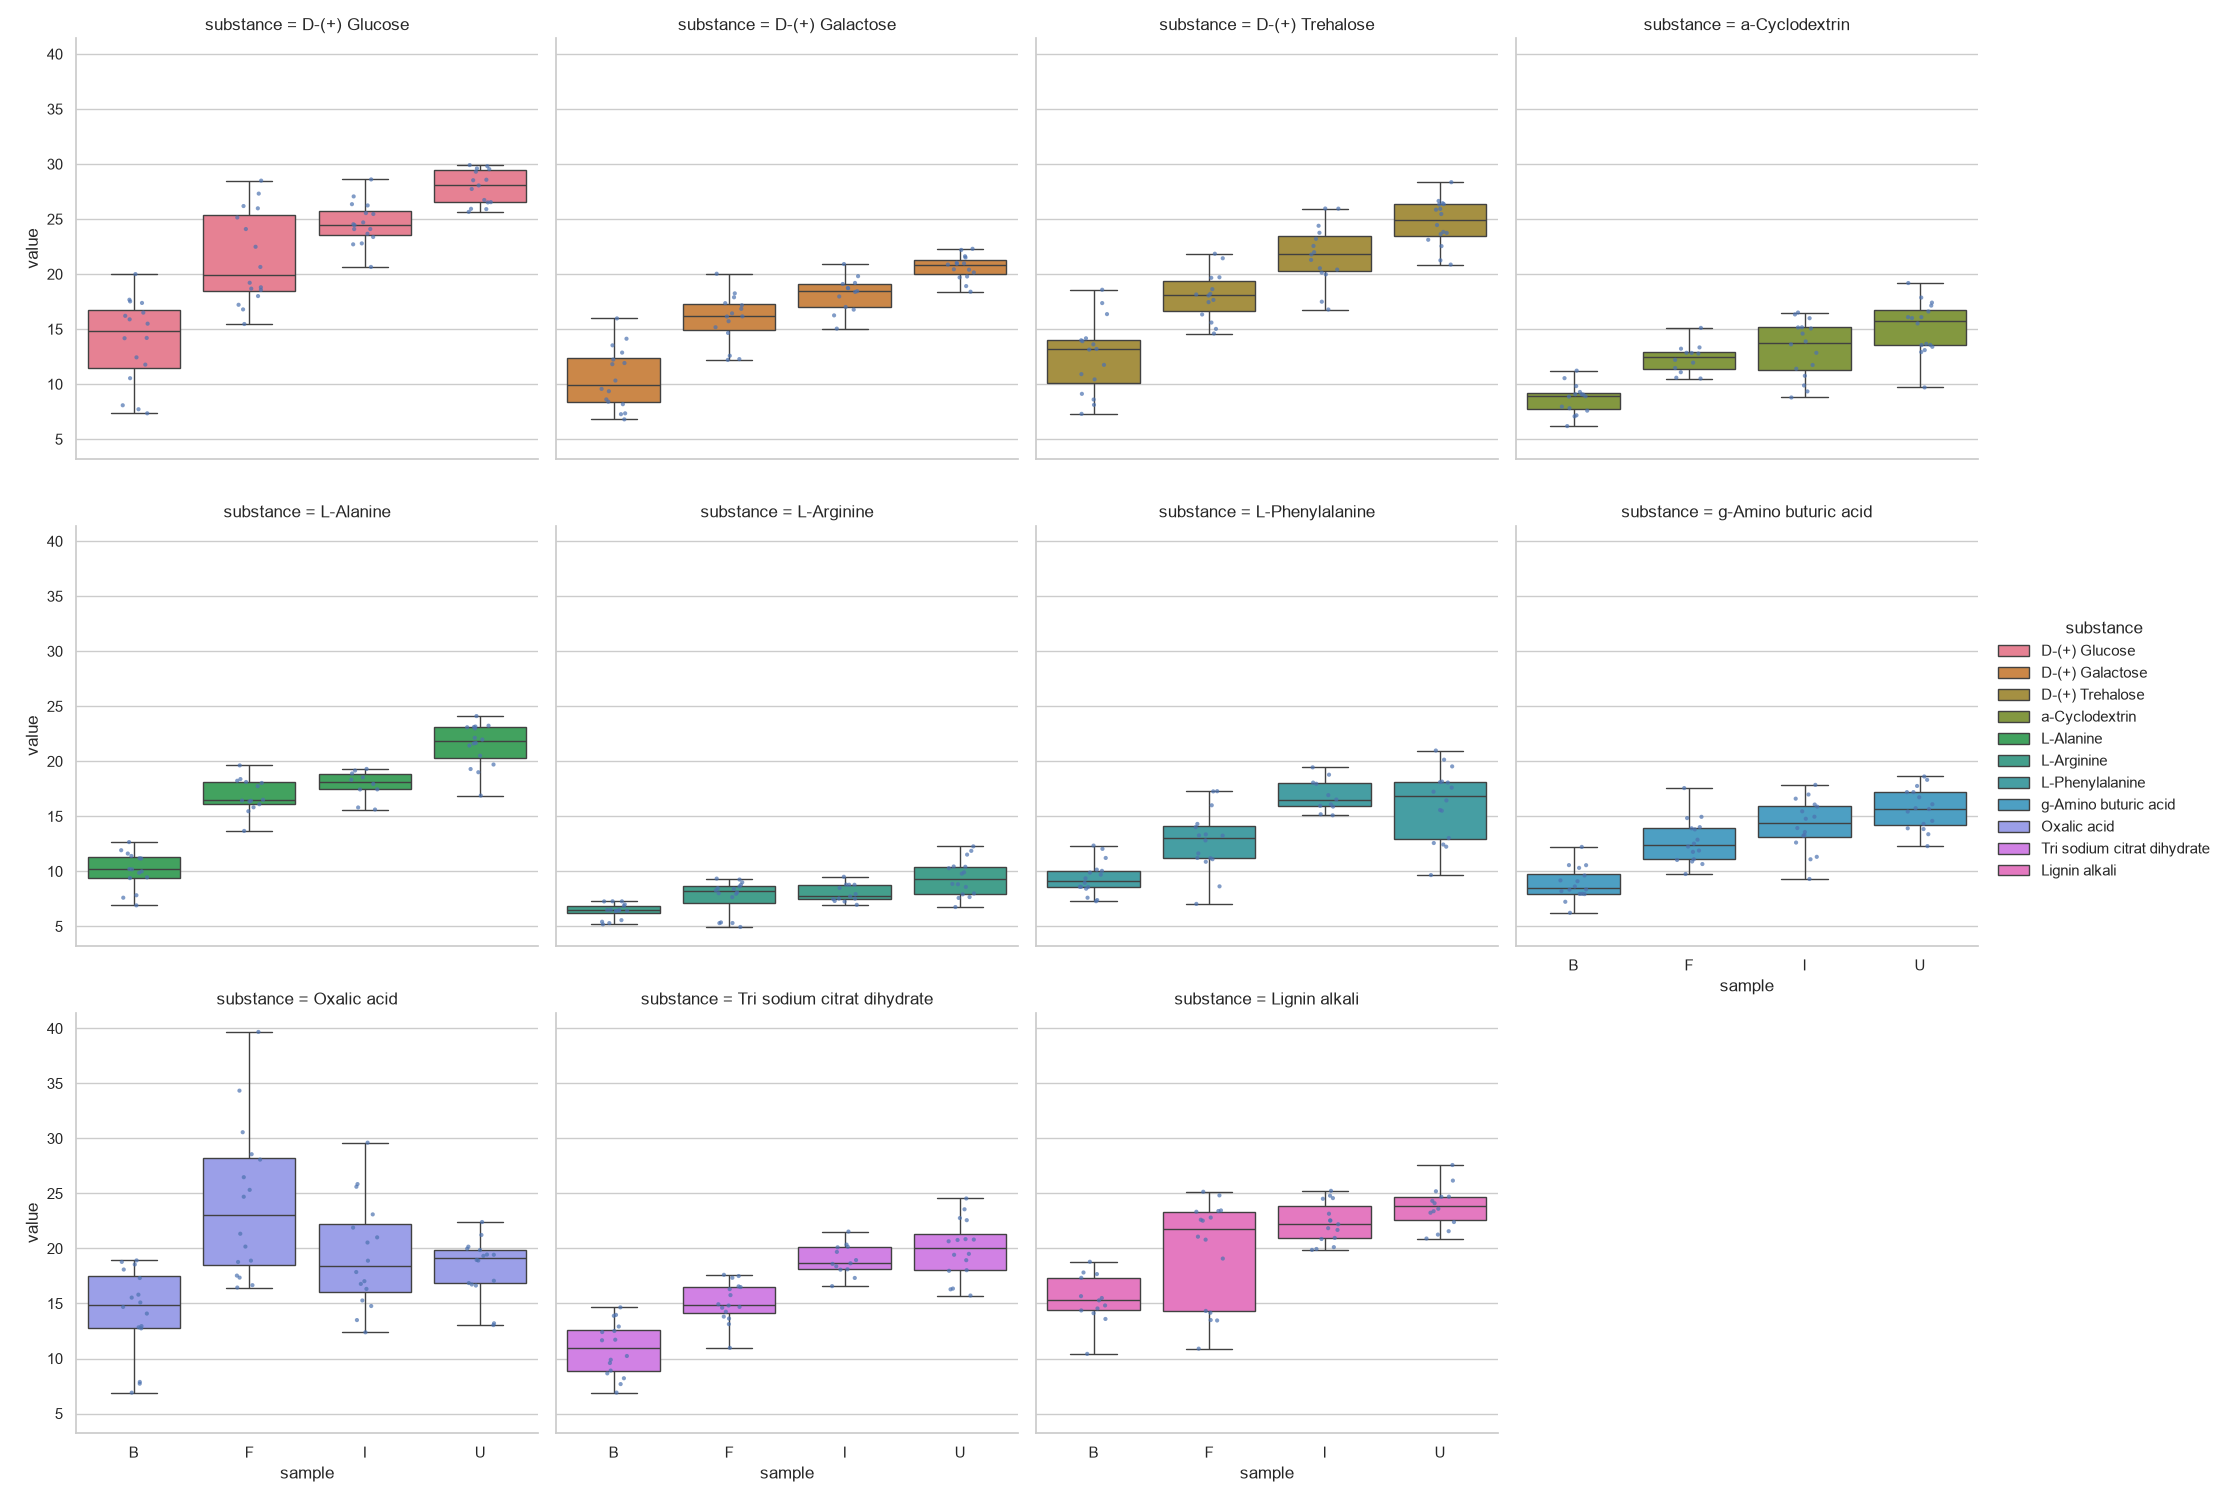

In [ ]:
substance_list = list(substance_mapping.values())

plot = plot_sir_boxplots(df=subset_melt, mapping=substance_list)

save_plot(plot=plot, name="sir_boxplot")

# PCA

In [ ]:
from geo6.pca import prepare_pca_data, calc_pca, plot_pca, print_pca_loadings, perform_pca

### Microresp

In [ ]:
features = [
    'br_mg_per_g_h', 'sir_1_mg_per_g_h', 'sir_2_mg_per_g_h',
    'sir_3_mg_per_g_h', 'sir_4_mg_per_g_h', 'sir_5_mg_per_g_h', 
    'sir_6_mg_per_g_h', 'sir_7_mg_per_g_h', 'sir_8_mg_per_g_h',
    'sir_9_mg_per_g_h', 'sir_10_mg_per_g_h', 'sir_11_mg_per_g_h'
]

perform_pca(df=data.microresp, features=features)

## 

In [ ]:
# print(data.dissolved_carbon_nitrogen.columns)
features = ['doc_inc_mg_kg', 'dic_inc_mg_kg',
       'dc_inc_mg_kg', 'dn_inc_mg_kg', 'doc_froz_mg_kg', 'dic_froz_mg_kg',
       'dc_froz_mg_kg', 'dn_froz_mg_kg', 'dcn_inc_ratio', 'dcn_froz_ratio']

df_pca, X_scaled = prepare_pca_data(df=data.dissolved_carbon_nitrogen, features=features)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)
corr = X_scaled_df.corr()
print(corr.shape)

if corr is not None:
    plt.close("all")     
    sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap="vlag")
    plt.title("Correlation between MicroResp variables")
    plt.show()

else:
       print("corr is None")

In [ ]:
perform_pca(df=data.dissolved_carbon_nitrogen, features=features)

### Nitrification Rate

In [ ]:
nitrification_rate = data.nitrification_rate

# Select response vars
features = [
    # 'nitrate_n_mg_kg_dm', 'ammonium_n_mg_kg_dm', 
    'pnr_0_mg_per_kg_h_dm', 'pnr_0_ste',
    'pnr_W_mg_per_kg_h_dm', 'pnr_W_ste', 
    'pnr_F_mg_per_kg_h_dm', 'pnr_F_ste', 
    'pnr_I_mg_per_kg_h_dm', 'pnr_I_ste',
    'pnr_U_mg_per_kg_h_dm', 'pnr_U_ste'
]

df_pca, X_scaled = prepare_pca_data(df=nitrification_rate, features=features)

pca, df_scores = calc_pca(X_scaled=X_scaled, df_pca=df_pca)

plot_pca(df=df_scores, pca=pca)

print_pca_loadings(pca=pca, features=features)

## All

In [ ]:
data.cation_exchange_capacity.columns

In [ ]:
from functools import reduce
from dataclasses import fields

field_names = [field.name for field in fields(data)]
dfs = [getattr(data, name) for name in field_names]

keys = ['sample', 'type', 'subrep', 'group']

df_merged = reduce(
    lambda left, right: pd.merge(
        left,
        right,
        on=keys,
        how="outer",
        validate="one_to_one",
    ),
    dfs,
)

In [ ]:
# Select response vars
features = df_merged.drop(columns=['sample', 'type', 'subrep', 'group']).columns.to_list()

df_pca, X_scaled = prepare_pca_data(df=df_merged, features=features)

pca, df_scores = calc_pca(X_scaled=X_scaled, df_pca=df_pca)

plot_pca(df=df_scores, pca=pca)

print_pca_loadings(pca=pca, features=features)

In [ ]:
import plotly.graph_objects as go

# Sample scores
scores = df_scores.copy()

# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=["PC1", "PC2", "PC3"],
)

fig = go.Figure()

# Plot samples, colored by plant group
for group in scores["sample"].unique():
    subset = scores[scores["sample"] == group]

    fig.add_trace(go.Scatter3d(
        x=subset["PC1"],
        y=subset["PC2"],
        z=subset["PC3"],
        mode="markers",
        name=f"Group {group}",
        marker=dict(size=5),
    ))

# Scale loading vectors for visibility alongside sample scores
scale = scores[["PC1", "PC2", "PC3"]].abs().max().max()

for parameter, row in loadings.iterrows():
    x, y, z = row[["PC1", "PC2", "PC3"]] * scale

    fig.add_trace(go.Scatter3d(
        x=[0, x],
        y=[0, y],
        z=[0, z],
        mode="lines+text",
        name=parameter,
        text=["", parameter],
        textposition="top center",
        line=dict(width=4),
        showlegend=False,
        hovertemplate=f"{parameter}<extra></extra>",
    ))

fig.update_layout(
    title="3D PCA biplot: MicroResp measurements",
    scene=dict(
        xaxis_title=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
        yaxis_title=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
        zaxis_title=f"PC3 ({pca.explained_variance_ratio_[2]:.1%})",
    ),
    legend_title="Plant group",
)

fig.show()

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=["PC1", "PC2", "PC3"],
)

# The three PC combinations
pc_pairs = [
    ("PC1", "PC2"),
    ("PC1", "PC3"),
    ("PC2", "PC3"),
]

# Scale arrows for visibility alongside sample scores
score_max = df_scores[["PC1", "PC2", "PC3"]].abs().max().max()
loading_max = loadings.abs().to_numpy().max()
arrow_scale = score_max / loading_max * 0.7

for pc_x, pc_y in pc_pairs:
    fig = go.Figure()

    # Plot samples, colored by plant group
    for group in df_scores["sample"].unique():
        subset = df_scores[df_scores["sample"] == group]

        fig.add_trace(go.Scatter(
            x=subset[pc_x],
            y=subset[pc_y],
            mode="markers",
            name=f"Group {group}",
            marker=dict(size=8, opacity=0.8),
            hovertemplate=(
                f"Group: {group}<br>"
                f"{pc_x}: %{{x:.2f}}<br>"
                f"{pc_y}: %{{y:.2f}}"
                "<extra></extra>"
            ),
        ))

    # Plot parameter loading arrows
    for parameter, row in loadings.iterrows():
        x = row[pc_x] * arrow_scale
        y = row[pc_y] * arrow_scale

        # Draw arrow from origin to loading position
        fig.add_annotation(
            x=x,
            y=y,
            ax=0,
            ay=0,
            xref="x",
            yref="y",
            axref="x",
            ayref="y",
            showarrow=True,
            arrowhead=2,
            arrowsize=1,
            arrowwidth=1.5,
        )

        # Place feature name at the arrow tip
        fig.add_trace(go.Scatter(
            x=[x],
            y=[y],
            mode="text",
            text=[parameter],
            textposition="top center",
            textfont=dict(size=10),
            showlegend=False,
            hoverinfo="skip",
        ))

    # Axis labels include explained variance
    x_idx = int(pc_x[-1]) - 1
    y_idx = int(pc_y[-1]) - 1

    fig.update_layout(
        title=f"PCA biplot: {pc_x} vs. {pc_y}",
        xaxis_title=(
            f"{pc_x} "
            f"({pca.explained_variance_ratio_[x_idx]:.1%} variance)"
        ),
        yaxis_title=(
            f"{pc_y} "
            f"({pca.explained_variance_ratio_[y_idx]:.1%} variance)"
        ),
        template="plotly_white",
        width=1000,
        height=750,
        hovermode="closest",
    )

    # Equal axis scaling makes arrow directions easier to compare
    fig.update_yaxes(scaleanchor="x", scaleratio=1)

    fig.show()

## Else

In [ ]:
copper = data.copper
copper_sub = copper[["sample", "cu_ex_ug_kg_dm", "cu_org_ug_kg_dm", "cu_red_ug_kg_dm"]]


copper_agg = (
    copper_sub
    .groupby("sample")
    .agg(
        ["mean", "std"]
    )
    .reset_index()
)

In [ ]:
data_cols = copper_agg.drop(columns="sample").columns.to_list()

mean_cols = [col[0] for col in data_cols if col[1] == "mean"]
std_cols = [col[0] for col in data_cols if col[1] == "std"]


fig, axs = plt.subplots(figsize=(12, 4), ncols=3)

for i, col in enumerate(mean_cols):
    
    axs[i].bar(
        x=copper_agg["sample"],
        height=copper_agg[col]["mean"]
    )